In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from plots import *
from helper import *

In [2]:
df_prices = pd.read_csv("C:/Users/redli/OneDrive/Desktop/classic ml tasks/regression/Hourly_Gasoline_Prices.csv")
df_fuel_st_info = pd.read_csv(r"C:\Users\redli\OneDrive\Desktop\classic ml tasks\regression\Fuel_Station_Information.csv")

In [3]:
print(df_prices.shape)

(2503665, 4)


In [4]:
print(df_fuel_st_info.shape)

(22141, 8)


In [5]:
df_fuel_st_info.head(30)

,Id,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,53637,ODELLI LUCIA,Pompe Bianche,Stradale,NaN,NaN,NaN,NaN
1,52829,ERRA NICOLA,Api-Ip,Stradale,NaN,NaN,40.716039,14.941328
2,52614,FONZI PAOLO,Api-Ip,Stradale,stazione di servizio IP di Fonzi Paolo,NaN,NaN,NaN
3,53552,KHALIL NOMAN,Agip Eni,Stradale,NaN,CINISELLO BALSAMO,NaN,NaN
4,23778,ALFONSO DI BENEDETTO CARBURANTI LUBRIFICANTI SRL,Sicilpetroli,Stradale,A. Di Benedetto srl Via Imera Ag,AGRIGENTO,37.312391,13.585913
5,49195,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG021,AGRIGENTO,37.298234,13.589792
6,49460,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG023,AGRIGENTO,37.326120,13.591820
7,49459,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG024,AGRIGENTO,37.274324,13.614224
8,49199,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG025,AGRIGENTO,37.277103,13.610695
9,49196,EOS SERVICES S.R.L. A SOCIO UNICO,Q8,Stradale,AG027,AGRIGENTO,37.314948,13.571371


In [6]:
df_prices.head(30)

,Id,isSelf,Price,Date
0,51169,1,1.943,2022-01-01 11:45:53
1,44566,1,1.725,2022-01-02 11:15:08
2,44566,0,1.775,2022-01-02 11:15:08
3,20026,1,1.729,2022-01-02 11:27:01
4,12494,0,1.559,2022-01-02 12:07:25
5,12494,1,1.559,2022-01-02 12:07:25
6,37593,0,1.789,2022-01-02 12:36:25
7,37593,1,1.789,2022-01-02 12:36:25
8,50047,0,1.879,2022-01-02 14:20:37
9,52185,0,1.800,2022-01-02 17:25:08


In [7]:
df_prices.info()

<class 'pandas.DataFrame'>
RangeIndex: 2503665 entries, 0 to 2503664
Data columns (total 4 columns):
 #   Column  Dtype  
---  ------  -----  
 0   Id      int64  
 1   isSelf  int64  
 2   Price   float64
 3   Date    str    
dtypes: float64(1), int64(2), str(1)
memory usage: 76.4 MB


In [8]:
df_fuel_st_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 22141 entries, 0 to 22140
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Id                    22141 non-null  int64  
 1   Fuel_station_manager  22141 non-null  str    
 2   Petrol_company        22141 non-null  str    
 3   Type                  22141 non-null  str    
 4   Station_name          22134 non-null  str    
 5   City                  22138 non-null  str    
 6   Latitude              22133 non-null  float64
 7   Longitudine           22133 non-null  float64
dtypes: float64(2), int64(1), str(5)
memory usage: 1.4 MB


In [9]:
df_prices.describe()

,Id,isSelf,Price
count,2.503665e+06,2.503665e+06,2.503665e+06
mean,3.308843e+04,6.149281e-01,1.832323e+00
std,1.530675e+04,4.866124e-01,1.786414e-01
min,3.464000e+03,0.000000e+00,1.940000e-01
25%,2.021400e+04,0.000000e+00,1.689000e+00
50%,3.546800e+04,1.000000e+00,1.799000e+00
75%,4.700500e+04,1.000000e+00,1.954000e+00
max,5.525300e+04,1.000000e+00,9.999000e+00


In [10]:
df_fuel_st_info.describe()

,Id,Latitude,Longitudine
count,22141.000000,22133.000000,22133.000000
mean,32392.033422,42.915804,12.155349
std,15365.070158,2.551807,2.613668
min,3464.000000,2.243470,6.709295
25%,18677.000000,40.988158,10.133089
50%,34772.000000,43.539096,12.230324
75%,46561.000000,45.230834,14.144690
max,54174.000000,46.946944,18.496371


In [11]:
df_prices_eda = df_prices.copy()
df_fuel_st_info = df_fuel_st_info.copy()

In [12]:
duplicates_in_prices = (df_prices.duplicated() == True).sum()
print(duplicates_in_prices)

59328


In [13]:
df_full_eda = pd.merge(df_prices_eda, df_fuel_st_info, how = "inner", on = "Id")
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
6,37593,0,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
7,37593,1,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093
9,52185,0,1.800,2022-01-02 17:25:08,PIRA GIANPAOLO,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334


In [14]:
df_full_eda.shape

(2451429, 11)

In [15]:
df_full_eda.isna().sum()

Id                        0
isSelf                    0
Price                     0
Date                      0
Fuel_station_manager      0
Petrol_company            0
Type                      0
Station_name            253
City                    226
Latitude                504
Longitudine             504
dtype: int64

In [16]:
df_full_eda["Station_name"].unique()

<StringArray>
[                             'BAUDUCCHI OVEST',
                                         'EASY',
                                           'IP',
      'Impianto Verona Petroli - San Bonifacio',
                     'CARBURANTI PALAZZO SNC  ',
 'stzione di servizio Di Benedetto Maria Agata',
                               'PIRA GIANPAOLO',
                       'Distributore Eni Tocco',
                                          'eni',
                             'anselmetti david',
 ...
         'ROSSI RACING SAS - STAZIONE IP 48618',
                            'Bianchini Anna IP',
                                 'tamolil 7086',
                                'GIANO VETUSTO',
               'SANTANA SANTANA YOLANDY YOSENI',
                                     'ENI 7271',
                          'IP PACELLI GIOVANNI',
                                    'ENCAR SRL',
                'ARTICOLO 80 DI BICARINI MARCO',
                                       'lukoil']
L

In [17]:
df_full_eda["Station_name"].nunique()

17865

Значений stationn_name слишком много, они будут создавать лишний шум, что плохо скажется на итоговом результате, поэтому этот признак я упущу, так же часть инфомрации из этого признака содержится в признаки petrol_company

In [18]:
df_full_eda.drop(["Station_name"], axis =1)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,SAN BONIFACIO,45.386059,11.273766
...,...,...,...,...,...,...,...,...,...,...
2451424,48073,0,1.869,2022-12-31 07:59:50,CALOR SYSTEMS S.R.L.,Api-Ip,Stradale,PIOLTELLO,45.503685,9.330787
2451425,48073,1,1.639,2022-12-31 07:59:50,CALOR SYSTEMS S.R.L.,Api-Ip,Stradale,PIOLTELLO,45.503685,9.330787
2451426,27829,0,1.659,2022-12-31 07:59:55,IP G.L. Carburanti e gomme,Api-Ip,Stradale,LANCIANO,42.225105,14.405091
2451427,14415,1,1.619,2022-12-31 07:59:57,SELF AREA AGIP DI FRANCOLINI FABIO & MORETTI G...,Agip Eni,Stradale,PESARO,43.896590,12.904783


In [19]:
df_full_eda["City"].nunique()

5312

In [20]:
print(df_full_eda["City"].isna().sum())
print(df_full_eda["City"].isnull().sum())
print((df_full_eda["City"] == " ").sum())

226
226
0


In [21]:
df_full_eda["City_missing"] = df_full_eda["City"].isna().astype(int)

In [22]:
df_full_eda["City"] = df_full_eda["City"].fillna("MISSING")

In [23]:
df_full_eda["City"].value_counts()

City
ROMA                  89952
MILANO                28743
PALERMO               22077
TORINO                20608
NAPOLI                19187
                      ...  
CARDE'                    1
PIEVE PORTO MORONE        1
CORTE BRUGNATELLA         1
DELIANUOVA                1
GIANO VETUSTO             1
Name: count, Length: 5313, dtype: int64

In [24]:
(df_full_eda["City"].value_counts() == 1).sum()/df_full_eda.shape[0]

np.float64(2.4475520196587377e-06)

In [25]:
df_full_eda["City"] = df_full_eda["City"].where(df_full_eda["City"].map(df_full_eda["City"].value_counts()) >= 20, "Other") 
df_full_eda["City"].value_counts()

City
ROMA           89952
MILANO         28743
PALERMO        22077
TORINO         20608
NAPOLI         19187
               ...  
ROCCAMENA         20
CAPOVALLE         20
GRAFFIGNANO       20
BORGO PACE        20
PIETRELCINA       20
Name: count, Length: 5249, dtype: int64

Доля строк. которым соответсвует уникальное для выборки значение маленькое, так что кодироваться эти значения будут при помощи targetencoding, с использованием сглаживания

In [26]:
df_full_eda["Fuel_station_manager"].value_counts()

Fuel_station_manager
IP SERVICES S.R.L.                                                                    151386
T.D.M. S.R.L.                                                                         100638
ENI FUEL S.P.A.                                                                        61130
SERVIZI & GESTIONI ITALIA S.R.L.                                                       57606
SERVIZI E GESTIONI ZENIT S.R.L. IN SIGLA - ZENIT S.R.L.                                53981
                                                                                       ...  
STAZIONE DI SERVIZIO ED AUTOFFICINA S. ANDREA S.N.C. DI BERNARDI IVAN & C.                 1
MINOPOLI LUIGI                                                                             1
IMPIANTO AGIP N. 4892 SEMENTA E PINI DI SEMENTA GIACOMO E PINI ALESSANDRO - S.N.C.         1
LIROSI MICHELE                                                                             1
GI.EFFE.A. DI ASTOLFI FRANCA E C. S.N.C.         

In [27]:
df_full_eda["Fuel_station_manager"] = df_full_eda["Fuel_station_manager"].where(
df_full_eda["Fuel_station_manager"].map(df_full_eda["Fuel_station_manager"].value_counts()) >= 20, "Other")
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine,City_missing
0,51169,1,1.943,2022-01-01 11:45:53,Other,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216,0
1,44566,1,1.725,2022-01-02 11:15:08,Other,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323,0
2,44566,0,1.775,2022-01-02 11:15:08,Other,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323,0
3,20026,1,1.729,2022-01-02 11:27:01,Other,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976,0
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,0
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,0
6,37593,0,1.789,2022-01-02 12:36:25,Other,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655,0
7,37593,1,1.789,2022-01-02 12:36:25,Other,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655,0
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093,0
9,52185,0,1.800,2022-01-02 17:25:08,Other,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334,0


Для признака Fuel_station будет использовано тоже самое что и для City

In [28]:
df_full_eda["Petrol_company"].nunique()

261

In [29]:
df_full_eda.isna().sum()

Id                        0
isSelf                    0
Price                     0
Date                      0
Fuel_station_manager      0
Petrol_company            0
Type                      0
Station_name            253
City                      0
Latitude                504
Longitudine             504
City_missing              0
dtype: int64

In [30]:
df_full_eda["Petrol_company"].value_counts()

Petrol_company
Agip Eni                 502895
Api-Ip                   464034
Tamoil                   301805
Pompe Bianche            281480
Esso                     265554
                          ...  
78                           20
Landini e Vignetti           19
MOVE 2                       19
COLAGROSSI CARBURANTI        18
europetroli                   4
Name: count, Length: 261, dtype: int64

In [31]:
sorted(list(df_full_eda["Petrol_company"].unique()))

['357',
 '4.0',
 '78',
 '7sette',
 'ACI',
 'ACI_CL',
 'AF Petroli',
 'AG energy',
 'ALIFUEL',
 'ALoil',
 'AP',
 'AP Stazioni di Servizio',
 'Acton1Q',
 'Adamo Idrocarburi',
 'Agip Eni',
 'Ala',
 'Api-Ip',
 'Aquila',
 'Argentario Carburanti',
 'Auchan',
 'BC',
 'BELTRALLO CARBURANTI',
 'BIG',
 'BLF',
 'BN petroli',
 'BP Bachiorrini Petroli',
 'Bartolucci',
 'Beneco',
 'Benza',
 'Bertelli Carburanti',
 'Beyfin',
 'Bianco Carburanti',
 'Bibbiena Carburanti',
 'Blanco petroli',
 'BluOil',
 'BluPark',
 'Bogoni',
 'Bolgan',
 'CENTRALE METANO FOLIGNO',
 'COIL',
 'COLAGROSSI CARBURANTI',
 'CONAD',
 'COOP',
 'CP',
 'Camer',
 'Cancellieri carburanti',
 'Canestrelli Petroli',
 'Capri Soc Coop',
 'CarbonOil',
 'Carburanti Paganelli',
 'CarburantiVecchietti',
 'Carrefour',
 'Carriero Energy',
 'Casareale',
 'Catria Energy',
 'Cler Carburanti',
 'Costa Carburanti',
 'Costantin',
 'Cristoforetti',
 'Cucagas',
 'Curreri Carburanti',
 'D Amico',
 'DBCarburanti',
 'DIS-CAR',
 'DV OIL',
 'Dall Aglio',
 '

In [32]:
df_full_eda["Petrol_company"] = df_full_eda["Petrol_company"].apply(lambda x: x.upper().strip())
df_full_eda["Petrol_company"].nunique()

261

In [33]:
df_full_eda["Petrol_company"].head()

0           API-IP
1             ESSO
2             ESSO
3           API-IP
4    POMPE BIANCHE
Name: Petrol_company, dtype: str

In [34]:
df_full_eda["Type"].nunique()

2

Далее буду работать с признаком времени покупки, для этого переведу время в значения количества минут и переведу значение Date в порядковое значение дня в году

In [35]:
import datetime as dt

In [36]:
df_full_eda["DateTime"] = pd.to_datetime(df_full_eda["Date"])
df_full_eda["Date"] = df_full_eda["DateTime"].apply(lambda x: x.date())
df_full_eda["Date"] = pd.to_datetime(df_full_eda["Date"])
df_full_eda["Time"] = df_full_eda["DateTime"].apply(lambda x: x.time())
df_full_eda["Time"] = df_full_eda["Time"].apply(lambda x: x.hour*60 + x.minute)
df_full_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 2451429 entries, 0 to 2451428
Data columns (total 14 columns):
 #   Column                Dtype         
---  ------                -----         
 0   Id                    int64         
 1   isSelf                int64         
 2   Price                 float64       
 3   Date                  datetime64[s] 
 4   Fuel_station_manager  str           
 5   Petrol_company        str           
 6   Type                  str           
 7   Station_name          str           
 8   City                  str           
 9   Latitude              float64       
 10  Longitudine           float64       
 11  City_missing          int64         
 12  DateTime              datetime64[us]
 13  Time                  int64         
dtypes: datetime64[s](1), datetime64[us](1), float64(3), int64(4), str(5)
memory usage: 261.8 MB


In [37]:
print(max(df_full_eda["Time"]))
print(min(df_full_eda["Time"]))

1439
0


In [38]:
df_full_eda.head(15)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine,City_missing,DateTime,Time
0,51169,1,1.943,2022-01-01,Other,API-IP,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216,0,2022-01-01 11:45:53,705
1,44566,1,1.725,2022-01-02,Other,ESSO,Stradale,EASY,GALLIPOLI,40.059118,18.032323,0,2022-01-02 11:15:08,675
2,44566,0,1.775,2022-01-02,Other,ESSO,Stradale,EASY,GALLIPOLI,40.059118,18.032323,0,2022-01-02 11:15:08,675
3,20026,1,1.729,2022-01-02,Other,API-IP,Stradale,IP,CAMPOMARINO,41.938508,15.076976,0,2022-01-02 11:27:01,687
4,12494,0,1.559,2022-01-02,BUSSINELLO S.R.L.,POMPE BIANCHE,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,0,2022-01-02 12:07:25,727
5,12494,1,1.559,2022-01-02,BUSSINELLO S.R.L.,POMPE BIANCHE,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,0,2022-01-02 12:07:25,727
6,37593,0,1.789,2022-01-02,Other,IES,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655,0,2022-01-02 12:36:25,756
7,37593,1,1.789,2022-01-02,Other,IES,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655,0,2022-01-02 12:36:25,756
8,50047,0,1.879,2022-01-02,DI BENEDETTO MARIA AGATA,SP ENERGIA SICILIANA,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093,0,2022-01-02 14:20:37,860
9,52185,0,1.800,2022-01-02,Other,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334,0,2022-01-02 17:25:08,1045


In [39]:
print(f"Перый день - {min(df_full_eda["Date"])}")
print(f"Последний день - {max(df_full_eda["Date"])}")

Перый день - 2022-01-01 00:00:00
Последний день - 2022-12-31 00:00:00


In [40]:
df_full_eda["Date"] = df_full_eda["Date"].dt.dayofyear

In [41]:
print(max(df_full_eda["Date"]))
print(min(df_full_eda["Date"]))

365
1


In [42]:
num_features = df_full_eda.select_dtypes(include=['number']).drop(['Id', 'isSelf', 'City_missing'], axis =1).columns.tolist()
cat_features = df_full_eda.select_dtypes(include=['object']).drop(['Station_name'], axis =1).columns.tolist()

C:\Users\redli\AppData\Local\Temp\ipykernel_1892\4125744784.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = df_full_eda.select_dtypes(include=['object']).drop(['Station_name'], axis =1).columns.tolist()


array([[<Axes: title={'center': 'Price'}>,
        <Axes: title={'center': 'Date'}>,
        <Axes: title={'center': 'Latitude'}>],
       [<Axes: title={'center': 'Longitudine'}>,
        <Axes: title={'center': 'Time'}>, <Axes: >]], dtype=object)

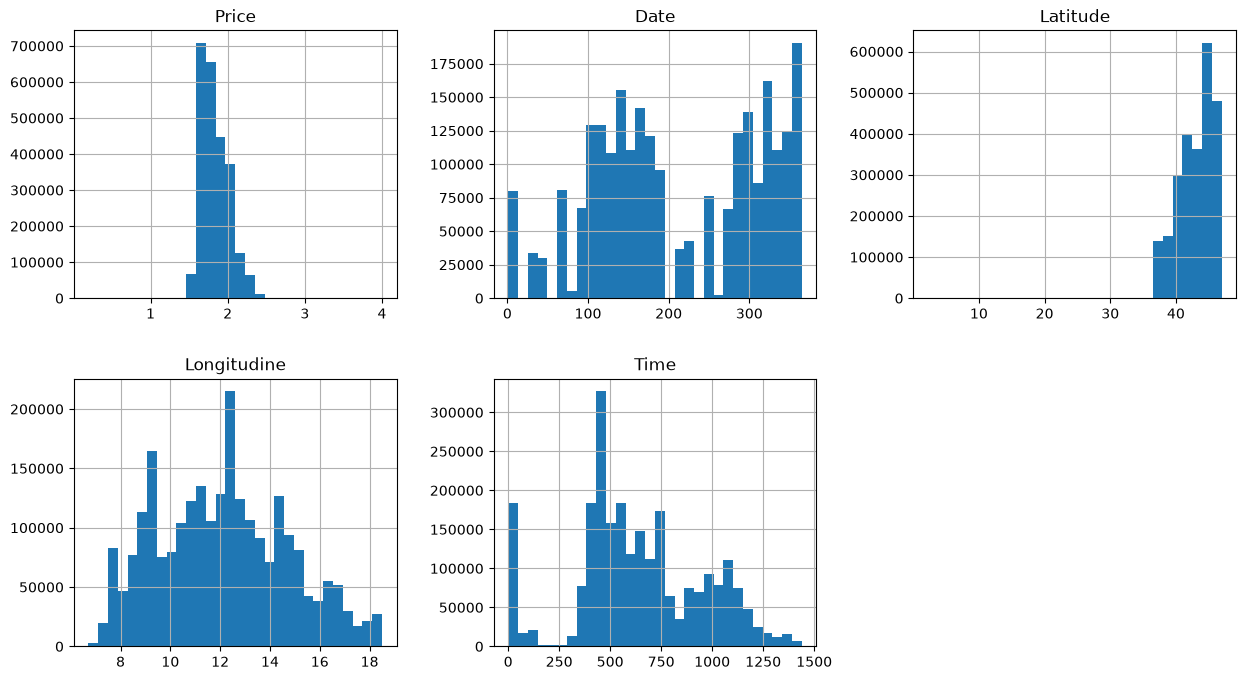

In [43]:
df_full_eda[num_features].hist(bins=30, figsize=(15, 8), layout=(2, 3))

Судя по графикам распределния:
- Price и Longitudine распределены нормально, Date имеет вид синусойды, пики количества изменений цены происходят дважды в год
- Latitude явно скошен вправо, очевидно, из-за географического расположения италии
- Time скошен влево, c заметным пиком в области 0, судя по графику время обновления цены происходят преимущественно с утра и часто в полночь
  

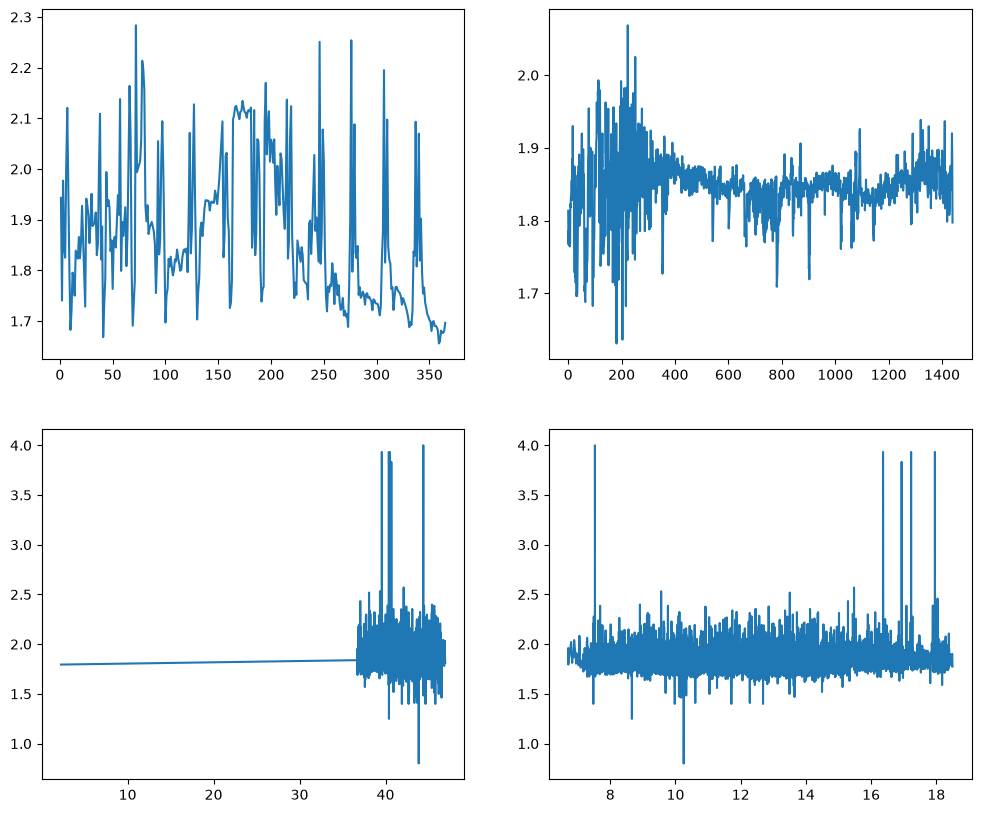

In [44]:
fig, ax = plt.subplots(nrows = 2, ncols = 2, figsize = (12,10))
num_cols = ["Date", "Time", "Latitude", "Longitudine"]
axes = ax.flatten()
for num in range(4):
    axes[num].plot(df_full_eda.groupby(num_cols[num])["Price"].mean())

In [45]:
df_full_eda.head(10)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine,City_missing,DateTime,Time
0,51169,1,1.943,1,Other,API-IP,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216,0,2022-01-01 11:45:53,705
1,44566,1,1.725,2,Other,ESSO,Stradale,EASY,GALLIPOLI,40.059118,18.032323,0,2022-01-02 11:15:08,675
2,44566,0,1.775,2,Other,ESSO,Stradale,EASY,GALLIPOLI,40.059118,18.032323,0,2022-01-02 11:15:08,675
3,20026,1,1.729,2,Other,API-IP,Stradale,IP,CAMPOMARINO,41.938508,15.076976,0,2022-01-02 11:27:01,687
4,12494,0,1.559,2,BUSSINELLO S.R.L.,POMPE BIANCHE,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,0,2022-01-02 12:07:25,727
5,12494,1,1.559,2,BUSSINELLO S.R.L.,POMPE BIANCHE,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,0,2022-01-02 12:07:25,727
6,37593,0,1.789,2,Other,IES,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655,0,2022-01-02 12:36:25,756
7,37593,1,1.789,2,Other,IES,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655,0,2022-01-02 12:36:25,756
8,50047,0,1.879,2,DI BENEDETTO MARIA AGATA,SP ENERGIA SICILIANA,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093,0,2022-01-02 14:20:37,860
9,52185,0,1.800,2,Other,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334,0,2022-01-02 17:25:08,1045


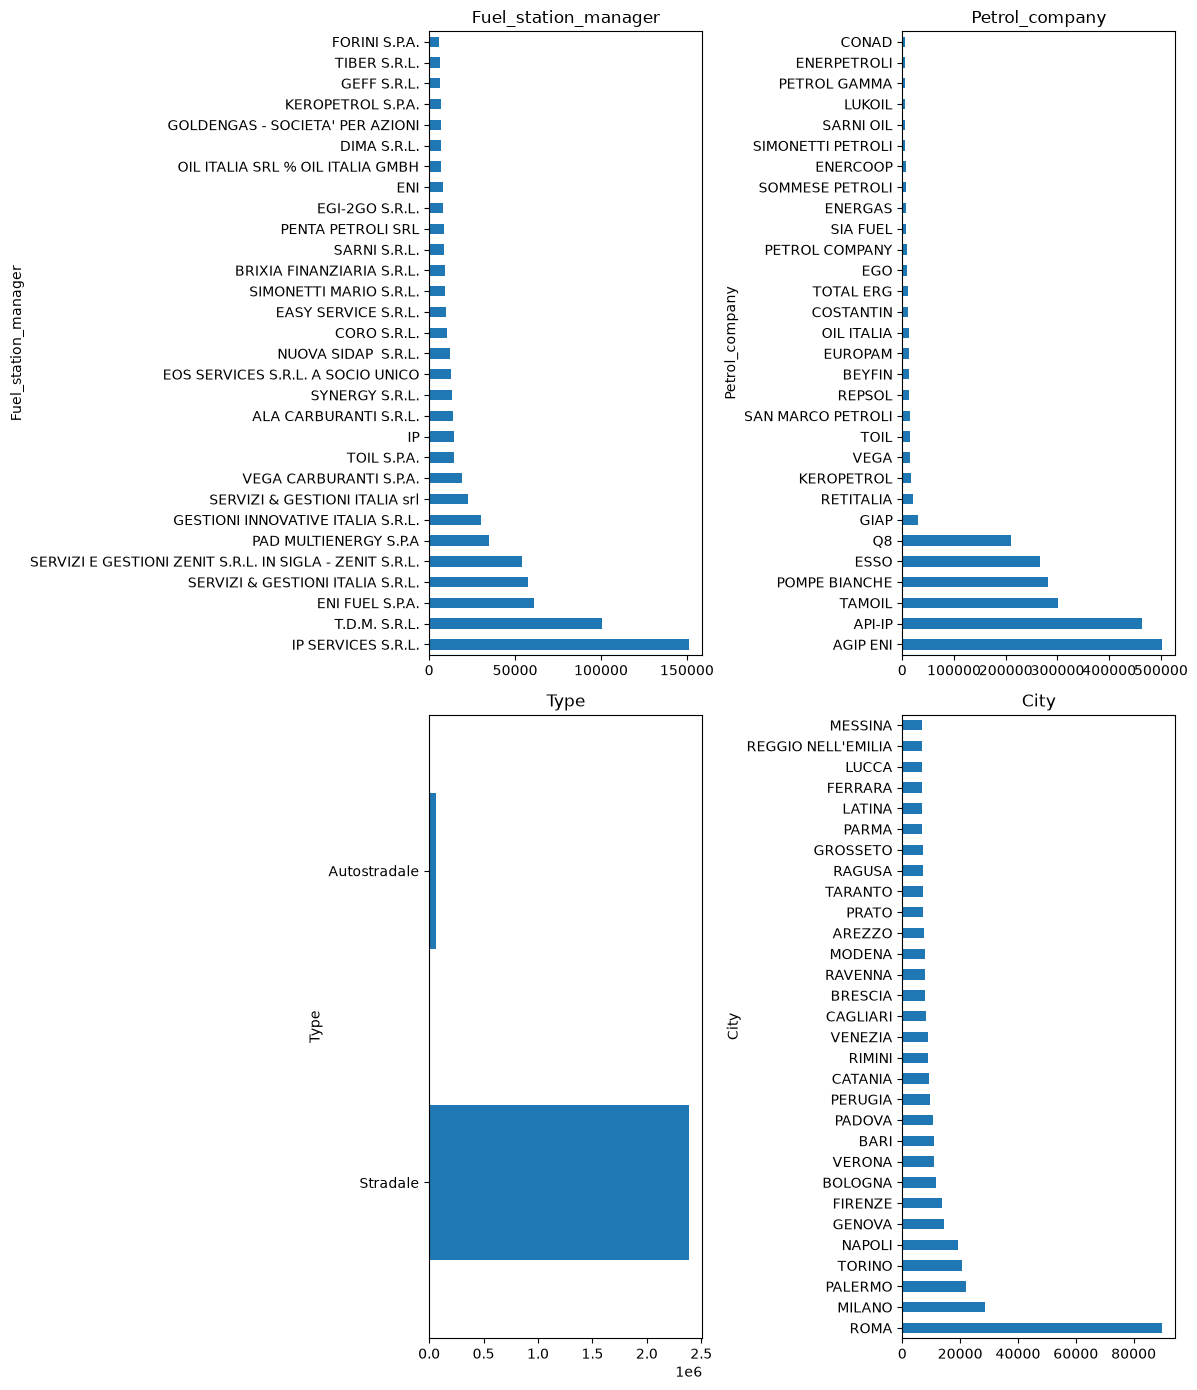

In [46]:
fig, ax = plt.subplots(nrows= 2, ncols= 2, figsize = (12, 14))
for ax, cat in zip(ax.ravel(), cat_features):
    df_full_eda[cat].value_counts().head(30).plot(kind="barh", ax=ax, title = cat)
    
plt.tight_layout()
plt.show()

In [47]:
print(df_full_eda["City"].isin(df_full_eda["City"].value_counts().nlargest(6).index).sum()/len(df_full_eda["City"]))
print(df_full_eda["City"].isin(df_full_eda["City"].value_counts().nlargest(100).index).sum()/len(df_full_eda["City"]))

0.07959806300733165
0.2780745434601614


Для большинства категориальных признаков характерен дисбаланс, уникальных значений для всех категорий кроме Type очень много, доля наиболее часто встречающихся не слишком большая

interval columns not set, guessing: ['isSelf', 'Price', 'Date', 'Latitude', 'Longitudine', 'City_missing', 'Time']


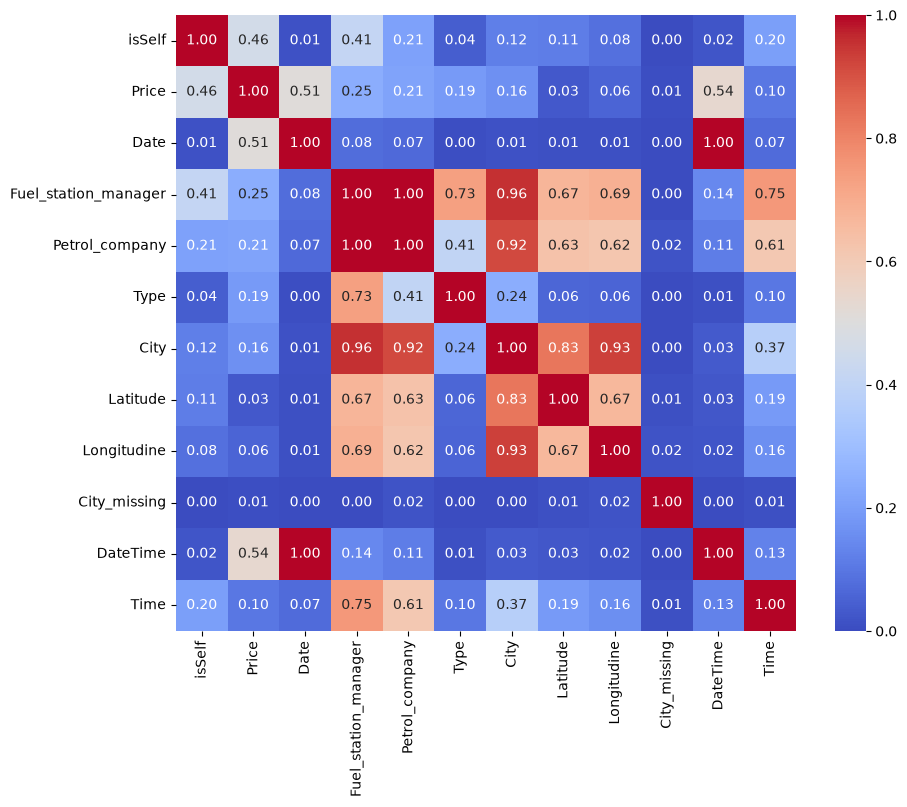

In [48]:
df_heatmap = df_full_eda.copy()
idxs = 0
for col in ["City", "Fuel_station_manager", "Petrol_company"]:
    idxs = df_heatmap[col].value_counts().nlargest(300).index
    df_heatmap[col] = df_heatmap[col].where(df_heatmap[col].isin(idxs), "Other")
df_heatmap["DateTime"] = pd.cut(df_heatmap["DateTime"], bins = 30)
plot_phik(df_heatmap.drop(["Station_name", "Id"], axis =1))
plt.show()

Наиболее значимые для таргета признаки - isSelf, Date, Fuel_station_manager, City, Datetime. Между признаками: Petrol_company, City, Fuel_station_manager, может сущетсвовать мультиколлинеарность, этот вопрос требует дальнейшего исследования 

In [49]:
plt.figure(figsize = (12, 10))
df_full_cords = df_full_eda.groupby(["Longitudine", "Latitude"], as_index = False)["Price"].mean()
df_full_cords.head()

,Longitudine,Latitude,Price
0,6.709295,45.075939,1.802158
1,6.710971,45.081721,1.961099
2,6.712999,45.074832,1.795264
3,6.799269,44.973283,2.022333
4,6.831698,45.031271,1.812103


<Figure size 1200x1000 with 0 Axes>

(36.0, 50.0)

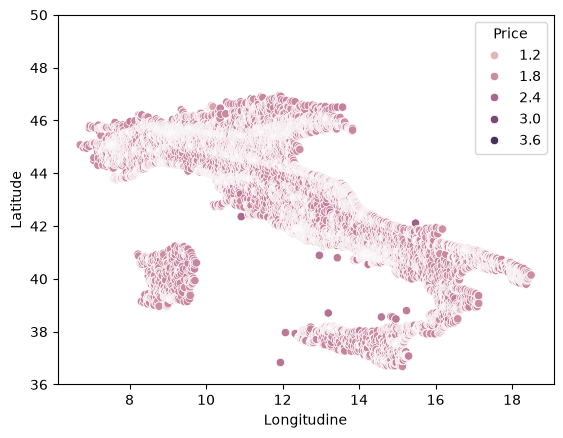

In [50]:
sns.scatterplot(data = df_full_cords, x= "Longitudine", y= "Latitude", hue= "Price")
plt.ylim(36, 50)

График изображаает площадь Италии. Цены распределены примерно одинаково, отчетливо видны пики на удаленных заправках. Возможно выборсы, но с таким количеством записей (2.5 миллиона), небольшое количество выбросов не должно влиять на итоговый результат

<Axes: xlabel='isSelf', ylabel='Price'>

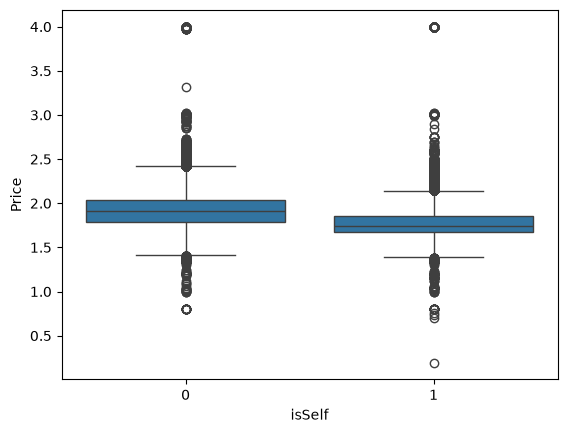

In [51]:
df_full_eda
sns.boxplot(data = df_full_eda, x = "isSelf", y = "Price", )


Для значения ноль существует кластер выбросов в районе 4.0, похоже на заглушку

In [52]:
from statsmodels.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

num = add_constant(df_full_eda[["Longitudine", "Latitude"]].dropna().sample(n = 100000, random_state = 42))

vif = pd.Series([variance_inflation_factor(num.values, i) for i in range(1, num.shape[1])], index = num.columns[1:])
print(vif)

Longitudine    1.840375
Latitude       1.840375
dtype: float64


VIF показл небольшие значения, Longitudine и Latitude показывают небольшую корреляцию, но видимо только друг с другом, так что все признаки можно оставить

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, OneHotEncoder

In [54]:
manager_encoder = TargetEncoder(smooth='auto', cv=5)
company_encoder = TargetEncoder(smooth='auto', cv=5)
type_encoder = OneHotEncoder(drop = "first", sparse_output=False)
def city_encoder(df):
    return df["City"].map(df["City"].value_counts())

In [55]:
df_full_eda["City"] = city_encoder(df_full_eda)

In [56]:
df_full_eda["Fuel_station_manager"] = manager_encoder.fit_transform(df_full_eda[["Fuel_station_manager"]], df_full_eda["Price"])
df_full_eda["Petrol_company"] = company_encoder.fit_transform(df_full_eda[["Petrol_company"]], df_full_eda["Price"])
type_encoder.fit(df_full_eda[["Type"]], df_full_eda["Price"])
df_full_eda["Type"] = type_encoder.transform(df_full_eda[["Type"]])

In [57]:
df_full_eda.head()

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine,City_missing,DateTime,Time
0,51169,1,1.943,1,1.880755,1.841082,0.0,BAUDUCCHI OVEST,2473,44.977978,7.700216,0,2022-01-01 11:45:53,705
1,44566,1,1.725,2,1.877548,1.861691,1.0,EASY,851,40.059118,18.032323,0,2022-01-02 11:15:08,675
2,44566,0,1.775,2,1.881614,1.861504,1.0,EASY,851,40.059118,18.032323,0,2022-01-02 11:15:08,675
3,20026,1,1.729,2,1.880986,1.841082,1.0,IP,723,41.938508,15.076976,0,2022-01-02 11:27:01,687
4,12494,0,1.559,2,1.749799,1.794686,1.0,Impianto Verona Petroli - San Bonifacio,672,45.386059,11.273766,0,2022-01-02 12:07:25,727


In [58]:
from sklearn.model_selection import cross_val_score, GroupKFold
from lightgbm import LGBMRegressor

check = [[], ["Fuel_station_manager"], ["City"], ["Fuel_station_manager", "City"]]
res = []

cv = GroupKFold(n_splits=5)
model = LGBMRegressor(verbose = -1, n_estimators = 200)

features = ["isSelf", "Date", "Type", "Latitude", "Longitudine", "Petrol_company"]
def score(features):
   return cross_val_score(model, X = df_full_eda[features], y = df_full_eda["Price"], groups = df_full_eda["Id"], scoring="neg_mean_absolute_error", cv=cv)
for i in range(4): 
   res.append(score(features+check[i]))
   print(f"C {check[i]} {res[i]}")
   print(f"Разница - {res[0].mean() - res[i].mean()}")

C [] [-0.04910952 -0.04934087 -0.04941076 -0.04883183 -0.04886771]
Разница - 0.0
C ['Fuel_station_manager'] [-0.04131663 -0.04117237 -0.04080229 -0.04118091 -0.04126611]
Разница - -0.007964476845933863
C ['City'] [-0.0494677  -0.04913456 -0.04873456 -0.04878041 -0.0486549 ]
Разница - -0.0001577131051186051
C ['Fuel_station_manager', 'City'] [-0.04105452 -0.04083376 -0.04057824 -0.04112855 -0.04093465]
Разница - -0.008206194328952233


In [59]:
print(f" Разница c Сity и с координатами: {score(["isSelf", "Date", "Type", "City", "Petrol_company"]).mean() - res[0].mean()}")

 Разница c Сity и с координатами: -0.0008328972355173964


Судя по тому, что демонстрирует результат кросс валидации, есть смысл осавить Fuel_station_manager и убрать City, судя по результатам последней проверки, параметры координат несут достаточно информации, слегка улучшая MAE в сравнении с результатом с City вместо координат